In [31]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

HEATMAP_DIR = 'Results/heatmaps'
os.makedirs(HEATMAP_DIR, exist_ok=True)

In [32]:
# ── Experiment list ──────────────────────────────────────────────────────────
# Add or remove entries freely.  The loader handles two formats automatically:
#
#   Coarse scans  BPDwf shape (steps, 4, samples)  — axis-1 = oscilloscope channel
#                 Set ch= to the BPD channel index (2 for July 31 data).
#
#   Fine scans    BPDwf shape (steps, 10, samples) — axis-1 = repeated shots
#                 All 10 shots are averaged first, then baseline-stripped.
#                 ch is ignored for fine scans.

coarse_scans = [
    {'label': '0.5 nC (coarse)', 'path': 'Data_raw/July31_/CoarseScan0p5nC_5_1.npz',  'ch': 2},
    {'label': '1 nC (coarse)',   'path': 'Data_raw/July31_/CoarseScan1nC_6_6.npz',    'ch': 2},
    {'label': '4 nC (coarse)',   'path': 'Data_raw/July31_/CoarseScan4nC_4_5.npz',    'ch': 2},
    {'label': '7 nC (coarse)',   'path': 'Data_raw/July31_/CoarseScan7nC_4_2.npz',    'ch': 2},
    {'label': '10 nC (coarse)', 'path': 'Data_raw/July31_/CoarseScan10nC_4_0.npz',   'ch': 2},
]

fine_scans = [
    {'label': '0.25 nC (fine)', 'path': 'Data_raw/July31_/finescaneQ0p25nC_wh5_4.npz'},
    {'label': '0.5 nC (fine)',  'path': 'Data_raw/July31_/finescaneQ0p5nC_wh5_1.npz'},
    {'label': '1 nC (fine)',    'path': 'Data_raw/July31_/finescaneQ1nC_wh5_6.npz'},
    {'label': '4 nC (fine)',    'path': 'Data_raw/July31_/finescaneQ4nC_wh4_5.npz'},
    {'label': '5 nC (fine)',    'path': 'Data_raw/July31_/finescaneQ5nC_wh4_3.npz'},
    {'label': '7 nC (fine)',    'path': 'Data_raw/July31_/finescaneQ7nC_wh4_2.npz'},
    {'label': '10 nC (fine)',   'path': 'Data_raw/July31_/finescaneQ10nC_wh4_0.npz'},
]

# Toggle which groups to include in the comparison plots
show_coarse = False
show_fine   = True

In [33]:

# ── Loader and baseline stripper ─────────────────────────────────────────────

from scipy.ndimage import uniform_filter1d

RF_Hz      = 81.25e6
mV         = 1e3
T_LASER_NS = 1e9 / RF_Hz   # ≈ 12.31 ns — one laser period

# ── Signal window definition ─────────────────────────────────────────────────
# The THz EO signal is known to appear only in [SIGNAL_START_NS, SIGNAL_END_NS].
# Flanks [0, SIGNAL_START_NS] and [SIGNAL_END_NS, FLANK_END_NS] are pure baseline.
SIGNAL_START_NS = 45.    # ns
SIGNAL_END_NS   = 75.    # ns
FLANK_END_NS    = 100.    # ns (end of right flank used for period-fill)

# ── Baseline mode ─────────────────────────────────────────────────────────────
# 'period_fill'  — per-trace; fills signal window from period-shifted flank data ← default
# 'mean_steps'   — subtract single global mean across all steps
# 'scaled_mean'  — per-step optimal amplitude scaling of the mean template
# 'rolling'      — per-trace rolling mean over one |sin| cycle
# 'svd'          — subtract leading SVD components (N_SVD=1 only safe)
BASELINE_MODE = 'period_fill'
N_SVD         = 1

# Half-window (samples) around the probe pulse for signed amplitude extraction.
PROBE_HALF_WIN = 25


def _period_fill_lookup(t_ns, signal_start, signal_end, flank_end):
    """
    Precompute source-sample lookup for the period-fill baseline.
    For each sample i in [i_sig0, i_sig1), returns:
      src_l[k]: sample index n periods BEFORE i, landing in [0, i_sig0)
      src_r[k]: sample index n periods AFTER  i, landing in [i_sig1, i_fl_end)
    All 1000 signal samples have both sources available (verified).
    """
    dt_ns    = (t_ns[-1] - t_ns[0]) / (len(t_ns) - 1)
    T_samp   = T_LASER_NS / dt_ns          # ≈ 615.4 samples per period
    i_sig0   = int(round(signal_start / dt_ns))
    i_sig1   = int(round(signal_end   / dt_ns))
    i_fl_end = int(round(flank_end    / dt_ns))

    idx  = np.arange(i_sig0, i_sig1)
    n_l  = np.ceil((idx + 1 - i_sig0) / T_samp).astype(int)
    n_r  = np.ceil((i_sig1 - idx)     / T_samp).astype(int)
    src_l = np.round(idx - n_l * T_samp).astype(int)
    src_r = np.round(idx + n_r * T_samp).astype(int)
    return i_sig0, i_sig1, src_l, src_r


def compute_baseline(traces, t_ns, mode, n_svd=N_SVD):
    if mode == 'period_fill':
        # Per-trace: baseline in flanks = raw trace (residual → 0 in flanks).
        # Baseline in signal window = average of the two nearest period-shifted
        # copies from the left and right flanks.  The laser period is 12.31 ns,
        # so both flanks always supply a valid copy for every signal sample.
        i_sig0, i_sig1, src_l, src_r = _period_fill_lookup(
            t_ns, SIGNAL_START_NS, SIGNAL_END_NS, FLANK_END_NS)
        baseline = traces.copy()
        baseline[:, i_sig0:i_sig1] = 0.5 * (traces[:, src_l] + traces[:, src_r])
        return baseline

    elif mode == 'mean_steps':
        mean_bl = traces.mean(axis=0)
        return np.tile(mean_bl, (traces.shape[0], 1))

    elif mode == 'scaled_mean':
        mean_bl = traces.mean(axis=0)
        scales  = (traces @ mean_bl) / (mean_bl @ mean_bl)
        return scales[:, np.newaxis] * mean_bl[np.newaxis, :]

    elif mode == 'rolling':
        dt_ns = (t_ns[-1] - t_ns[0]) / (len(t_ns) - 1)
        win   = max(1, int(round(T_LASER_NS / dt_ns)))
        return uniform_filter1d(traces, size=win, axis=-1, mode='reflect')

    elif mode == 'svd':
        U, sv, Vt = np.linalg.svd(traces, full_matrices=False)
        return (U[:, :n_svd] * sv[:n_svd]) @ Vt[:n_svd, :]

    else:
        raise ValueError(f"Unknown baseline_mode '{mode}'.")


def extract_signed_amplitude(residual, half_win=PROBE_HALF_WIN):
    """
    Return the signed EO signal E_THz(delay) for each phase step.
    Finds the probe-pulse time as the max-variance time column,
    then averages the residual over a ±half_win window there.
    """
    col_var = residual.var(axis=0)
    t_probe = col_var.argmax()
    n_samp  = residual.shape[1]
    win     = slice(max(0, t_probe - half_win), min(n_samp, t_probe + half_win))
    return residual[:, win].mean(axis=1)


def load_and_strip(path, ch=None, mode=BASELINE_MODE, n_svd=N_SVD):
    d        = np.load(path)
    BPDwf    = d['BPDwf']
    t_ns     = 1e9 * d['x'][0, :]
    phase    = d['phase']
    delay_ps = (phase - phase[0]) / RF_Hz / 360 * 1e12

    nchan = BPDwf.shape[1]
    if nchan == 10:
        traces = BPDwf.mean(axis=1)
    else:
        if ch is None:
            raise ValueError(f'ch must be specified for coarse scan (nchan={nchan})')
        traces = BPDwf[:, ch, :]

    baseline         = compute_baseline(traces, t_ns, mode, n_svd=n_svd)
    residual         = traces - baseline
    signed_amplitude = extract_signed_amplitude(residual)
    amplitude        = np.abs(signed_amplitude)

    return {'delay_ps': delay_ps, 'residual': residual,
            'signed_amplitude': signed_amplitude,
            'amplitude': amplitude,
            't_ns': t_ns, 'traces': traces}


# ── Load everything ───────────────────────────────────────────────────────────
results_coarse, results_fine = [], []

if show_coarse:
    print(f'Coarse scans  [baseline_mode={BASELINE_MODE}]:')
    for exp in coarse_scans:
        r = load_and_strip(exp['path'], ch=exp['ch'])
        r['label'] = exp['label']
        results_coarse.append(r)
        print(f"  {exp['label']:20s}  peak = {mV * r['amplitude'].max():.1f} mV  "
              f"delay range = {r['delay_ps'][-1]:.0f} ps")

if show_fine:
    print(f'Fine scans  [baseline_mode={BASELINE_MODE}]:')
    for exp in fine_scans:
        r = load_and_strip(exp['path'])
        r['label'] = exp['label']
        results_fine.append(r)
        print(f"  {exp['label']:20s}  peak = {mV * r['amplitude'].max():.1f} mV  "
              f"delay range = {r['delay_ps'][-1]:.0f} ps")


Fine scans  [baseline_mode=period_fill]:
  0.25 nC (fine)        peak = 12.5 mV  delay range = 136 ps
  0.5 nC (fine)         peak = 25.6 mV  delay range = 136 ps
  1 nC (fine)           peak = 44.9 mV  delay range = 136 ps
  4 nC (fine)           peak = 128.3 mV  delay range = 136 ps
  5 nC (fine)           peak = 167.4 mV  delay range = 136 ps
  7 nC (fine)           peak = 206.2 mV  delay range = 136 ps
  10 nC (fine)          peak = 241.9 mV  delay range = 136 ps


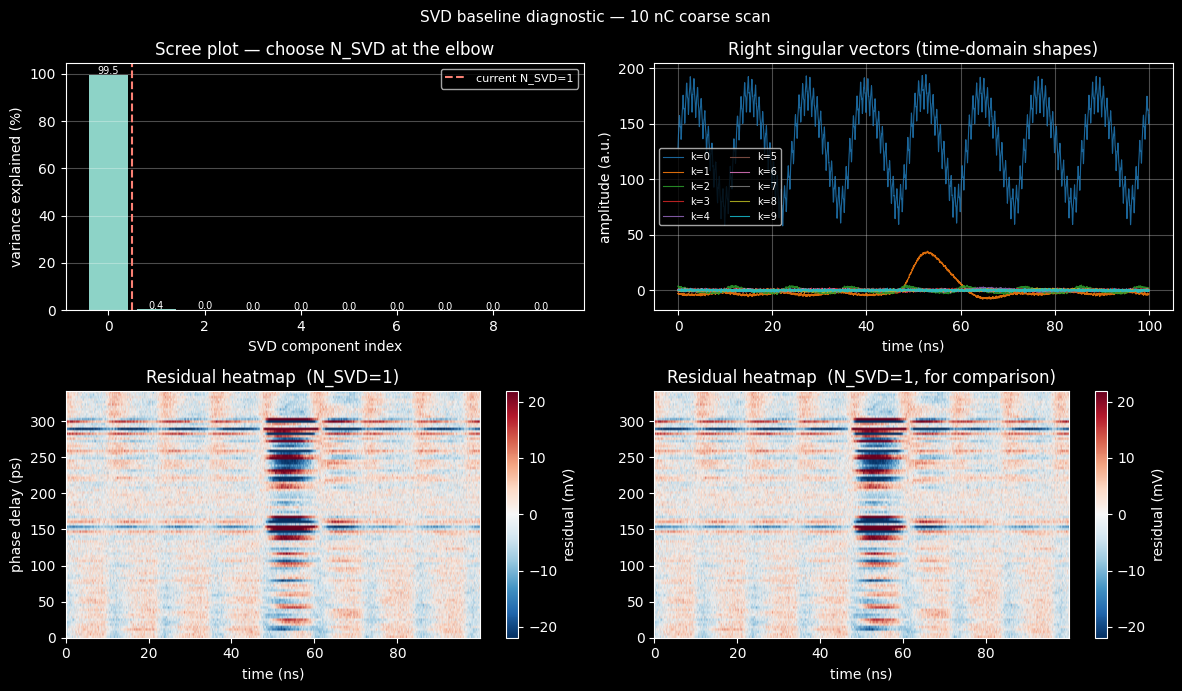

Variance explained by first 1 components: 99.47%
Residual RMS (N_SVD=1): 10.08 mV   (N_SVD=1): 10.08 mV   (mean_steps): 10.64 mV


In [34]:

# ── SVD diagnostic: scree plot + leading components ───────────────────────────
# Run this to decide how many components to subtract (N_SVD above).
# A clear "elbow" in the singular value spectrum separates baseline components
# (large sv) from signal+noise (flat tail).  The right singular vectors Vt[k,:]
# show the time-domain shape of each component — baseline components look like
# the |sin| envelope; signal components look like noise or THz-pulse-shaped transients.

# Use the highest-charge coarse scan as the diagnostic reference
_d      = np.load('Data_raw/July31_/CoarseScan10nC_4_0.npz')
_traces = _d['BPDwf'][:, 2, :]          # (101 steps, 5000 samples)
_t_ns   = 1e9 * _d['x'][0, :]
_phase  = _d['phase']
_delay  = (_phase - _phase[0]) / RF_Hz / 360 * 1e12

U, sv, Vt = np.linalg.svd(_traces, full_matrices=False)

n_show = 10   # how many components to display

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

# ── Scree plot: fraction of variance explained ────────────────────────────────
var_frac = sv**2 / (sv**2).sum()
ax = axes[0, 0]
ax.bar(np.arange(n_show), 100 * var_frac[:n_show], color='C0')
ax.set_xlabel('SVD component index')
ax.set_ylabel('variance explained (%)')
ax.set_title('Scree plot — choose N_SVD at the elbow')
for i, v in enumerate(var_frac[:n_show]):
    ax.text(i, 100 * v + 0.3, f'{100*v:.1f}', ha='center', fontsize=7)
ax.axvline(N_SVD - 0.5, color='C3', ls='--', lw=1.5, label=f'current N_SVD={N_SVD}')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3, axis='y')

# ── Right singular vectors: time-domain shape of each component ──────────────
ax = axes[0, 1]
colors = cm.tab10(np.linspace(0, 0.9, n_show))
for k in range(n_show):
    sign = np.sign(Vt[k, np.argmax(np.abs(Vt[k, :]))])   # normalise sign
    ax.plot(_t_ns, mV * sv[k] * sign * Vt[k, :] / len(_phase)**0.5,
            color=colors[k], lw=0.8, alpha=0.85, label=f'k={k}')
ax.set_xlabel('time (ns)')
ax.set_ylabel('amplitude (a.u.)')
ax.set_title('Right singular vectors (time-domain shapes)')
ax.legend(fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)

# ── Residual heatmap with current N_SVD ──────────────────────────────────────
bl  = (U[:, :N_SVD] * sv[:N_SVD]) @ Vt[:N_SVD, :]
res = _traces - bl
extent = [_t_ns[0], _t_ns[-1], _delay[0], _delay[-1]]
vmax = np.percentile(np.abs(mV * res), 98)
ax = axes[1, 0]
im = ax.imshow(mV * res, aspect='auto', extent=extent, origin='lower',
               cmap='RdBu_r', vmin=-vmax, vmax=vmax)
ax.set_title(f'Residual heatmap  (N_SVD={N_SVD})')
ax.set_xlabel('time (ns)')
ax.set_ylabel('phase delay (ps)')
plt.colorbar(im, ax=ax, label='residual (mV)')

# ── Residual heatmap with N_SVD=1 for comparison ─────────────────────────────
bl1  = U[:, :1] * sv[0] @ Vt[:1, :]
res1 = _traces - bl1
ax = axes[1, 1]
im1 = ax.imshow(mV * res1, aspect='auto', extent=extent, origin='lower',
                cmap='RdBu_r', vmin=-vmax, vmax=vmax)
ax.set_title('Residual heatmap  (N_SVD=1, for comparison)')
ax.set_xlabel('time (ns)')
plt.colorbar(im1, ax=ax, label='residual (mV)')

plt.suptitle('SVD baseline diagnostic — 10 nC coarse scan', fontsize=11)
plt.tight_layout()
plt.savefig(f'{HEATMAP_DIR}/svd_diagnostic.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"Variance explained by first {N_SVD} components: {100*var_frac[:N_SVD].sum():.2f}%")
print(f"Residual RMS (N_SVD={N_SVD}): {mV*res.std():.2f} mV   "
      f"(N_SVD=1): {mV*res1.std():.2f} mV   "
      f"(mean_steps): {mV*(_traces - np.tile(_traces.mean(axis=0), (len(_phase),1))).std():.2f} mV")


mean_steps:  peak=136.5 mV  RMS=10.64 mV  banding=3.210 mV
dipoleON:    peak=155.1 mV  RMS=18.91 mV  banding=0.078 mV

Scale factor range: 0.9532 – 1.1788  (1.0 = no drift, spread = laser power variation across steps)


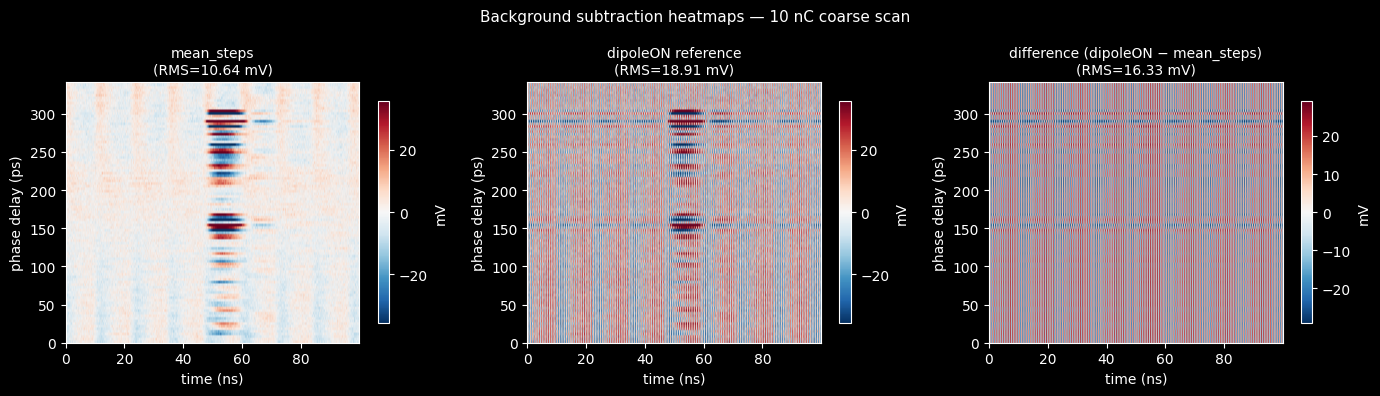

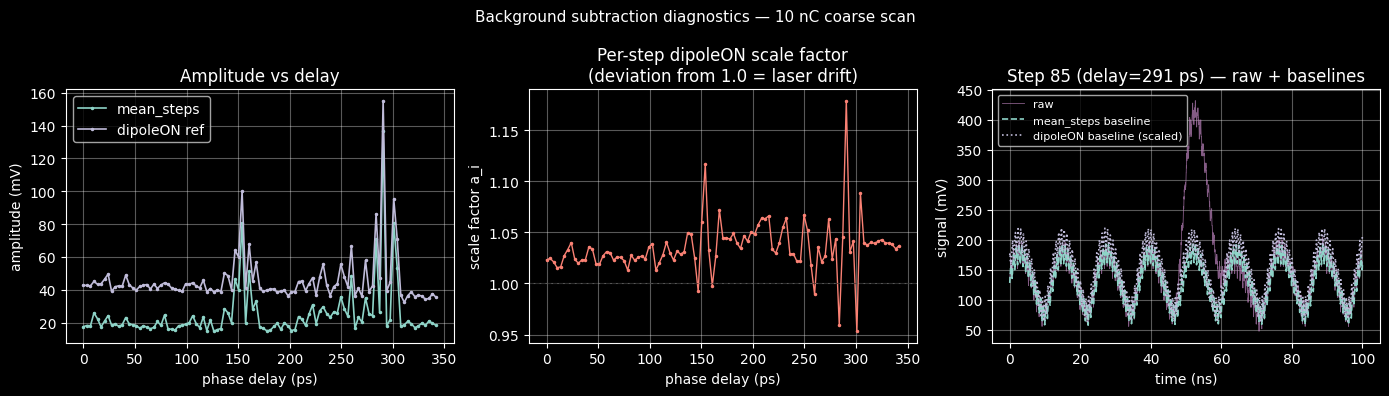

In [35]:

# ── dipoleON reference subtraction vs mean_steps — 10 nC coarse scan ─────────
# The dipoleON scan was taken immediately after the main scan with the dipole
# magnet deflecting the beam away from the EO crystal.  It captures the pure
# laser envelope with no THz contribution — the ideal physical background.
#
# Because the two acquisitions are ~10 min apart, the laser power drifted by
# ~5 mV DC.  We compensate with a per-step optimal scale factor (same approach
# as 'scaled_mean', but the template comes from dipoleON instead of the signal
# scan's own mean).
#
# All 5 dipoleON channels are averaged to get the cleanest possible template.

RF_Hz = 81.25e6
mV    = 1e3

# ── Load ─────────────────────────────────────────────────────────────────────
sig_raw  = np.load('Data_raw/July31_/CoarseScan10nC_4_0.npz')
bg_raw   = np.load('Data_raw/July31_/cosrsescaneQ10nC_wh4_0_dipoleON.npz')

sig_traces = sig_raw['BPDwf'][:, 2, :]          # (101, 5000)  ch=2 = BPD
t_ns       = 1e9 * sig_raw['x'][0, :]
phase_sig  = sig_raw['phase']
delay_ps   = (phase_sig - phase_sig[0]) / RF_Hz / 360 * 1e12

# dipoleON template: mean over all 5 channels and all 200 steps → (5000,)
bg_template = bg_raw['BPDwf'].mean(axis=(0, 1))

# ── Method 1: mean_steps ──────────────────────────────────────────────────────
mean_bl    = sig_traces.mean(axis=0)
res_mean   = sig_traces - mean_bl
amp_mean   = (res_mean.max(axis=1) - res_mean.min(axis=1)) / 2

# ── Method 2: dipoleON scaled subtraction ────────────────────────────────────
# For each step i, find a_i = argmin ||sig_i - a * bg_template||²
denom      = bg_template @ bg_template
scales     = (sig_traces @ bg_template) / denom         # (101,)
res_dipole = sig_traces - scales[:, np.newaxis] * bg_template
amp_dipole = (res_dipole.max(axis=1) - res_dipole.min(axis=1)) / 2

print(f"mean_steps:  peak={mV*amp_mean.max():.1f} mV  RMS={mV*res_mean.std():.2f} mV  "
      f"banding={mV*res_mean.mean(axis=1).std():.3f} mV")
print(f"dipoleON:    peak={mV*amp_dipole.max():.1f} mV  RMS={mV*res_dipole.std():.2f} mV  "
      f"banding={mV*res_dipole.mean(axis=1).std():.3f} mV")
print(f"\nScale factor range: {scales.min():.4f} – {scales.max():.4f}  "
      f"(1.0 = no drift, spread = laser power variation across steps)")

extent = [t_ns[0], t_ns[-1], delay_ps[0], delay_ps[-1]]

def heatmap(ax, data, title, vmax=None):
    vmax = vmax or np.percentile(np.abs(mV * data), 98)
    im = ax.imshow(mV * data, aspect='auto', extent=extent, origin='lower',
                   cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('time (ns)')
    ax.set_ylabel('phase delay (ps)')
    plt.colorbar(im, ax=ax, label='mV', shrink=0.85)
    return vmax

vmax = max(np.percentile(np.abs(mV * res_mean), 98),
           np.percentile(np.abs(mV * res_dipole), 98))

# ── Figure A: heatmaps only → saved to heatmaps directory ────────────────────
fig_hm, axes_hm = plt.subplots(1, 3, figsize=(14, 4))
heatmap(axes_hm[0], res_mean,           f'mean_steps\n(RMS={mV*res_mean.std():.2f} mV)', vmax)
heatmap(axes_hm[1], res_dipole,         f'dipoleON reference\n(RMS={mV*res_dipole.std():.2f} mV)', vmax)
heatmap(axes_hm[2], res_dipole-res_mean, f'difference (dipoleON − mean_steps)\n(RMS={mV*(res_dipole-res_mean).std():.2f} mV)')
fig_hm.suptitle('Background subtraction heatmaps — 10 nC coarse scan', fontsize=11)
plt.tight_layout()
plt.savefig(f'{HEATMAP_DIR}/dipoleON_heatmaps.png', dpi=200, bbox_inches='tight')
plt.show()

# ── Figure B: diagnostics (amplitude, scale factors, single step) ─────────────
fig_diag, axes_diag = plt.subplots(1, 3, figsize=(14, 4))

ax = axes_diag[0]
ax.plot(delay_ps, mV * amp_mean,   'C0.-', lw=1.2, markersize=3, label='mean_steps')
ax.plot(delay_ps, mV * amp_dipole, 'C2.-', lw=1.2, markersize=3, label='dipoleON ref')
ax.set_xlabel('phase delay (ps)')
ax.set_ylabel('amplitude (mV)')
ax.set_title('Amplitude vs delay')
ax.legend()
ax.grid(True, alpha=0.35)

ax = axes_diag[1]
ax.plot(delay_ps, scales, 'C3.-', lw=1, markersize=3)
ax.axhline(1.0, color='k', ls='--', lw=0.8, alpha=0.5)
ax.set_xlabel('phase delay (ps)')
ax.set_ylabel('scale factor a_i')
ax.set_title('Per-step dipoleON scale factor\n(deviation from 1.0 = laser drift)')
ax.grid(True, alpha=0.35)

step_idx = amp_mean.argmax()
ax = axes_diag[2]
ax.plot(t_ns, mV * sig_traces[step_idx], 'C7',  lw=0.6, alpha=0.7, label='raw')
ax.plot(t_ns, mV * mean_bl,              'C0',  lw=1.2, ls='--',   label='mean_steps baseline')
ax.plot(t_ns, mV * scales[step_idx] * bg_template, 'C2', lw=1.2, ls=':', label='dipoleON baseline (scaled)')
ax.set_xlabel('time (ns)')
ax.set_ylabel('signal (mV)')
ax.set_title(f'Step {step_idx} (delay={delay_ps[step_idx]:.0f} ps) — raw + baselines')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.35)

fig_diag.suptitle('Background subtraction diagnostics — 10 nC coarse scan', fontsize=11)
plt.tight_layout()
plt.savefig('Results/dipoleON_diagnostics.png', dpi=200, bbox_inches='tight')
plt.show()


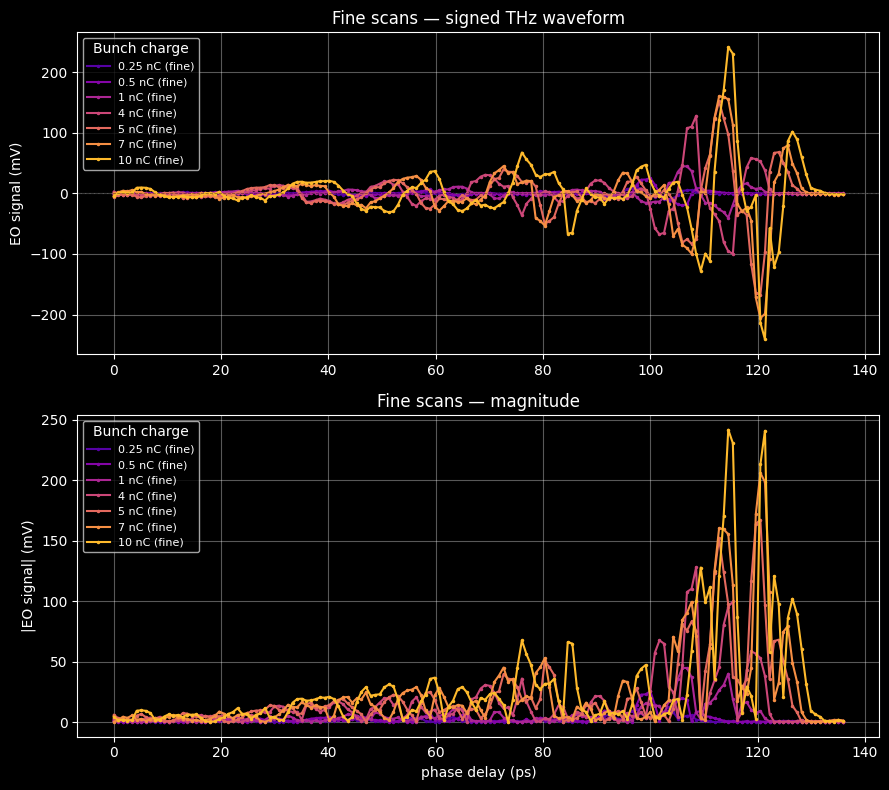

In [36]:
# ── Figure 1: EO waveform (signed) and magnitude — coarse and fine ────────────
# Top panel: signed amplitude vs delay — this IS the THz waveform E(t).
#   Positive = E_THz pushes BPD up; negative = pushes it down.
#   Sign changes are real: they reflect the bipolar THz electric field.
# Bottom panel: |signed| = magnitude, consistent with heatmap colour scale.

n_rows = sum([show_coarse, show_fine])
fig, axes = plt.subplots(n_rows * 2, 1, figsize=(9, 4 * n_rows * 2), squeeze=False)
ax_idx = 0

def plot_group_signed(ax_signed, ax_mag, results, title):
    colors = cm.plasma(np.linspace(0.15, 0.85, len(results)))
    for r, col in zip(results, colors):
        dp  = r['delay_ps']
        sig = mV * r['signed_amplitude']
        ax_signed.plot(dp, sig, color=col, lw=1.5, marker='.', markersize=3, label=r['label'])
        ax_mag.plot(dp, np.abs(sig), color=col, lw=1.5, marker='.', markersize=3, label=r['label'])
    ax_signed.axhline(0, color='k', lw=0.6, ls='--', alpha=0.4)
    ax_signed.set_ylabel('EO signal (mV)')
    ax_signed.set_title(f'{title} — signed THz waveform')
    ax_signed.legend(title='Bunch charge', fontsize=8)
    ax_signed.grid(True, alpha=0.35)
    ax_mag.set_xlabel('phase delay (ps)')
    ax_mag.set_ylabel('|EO signal| (mV)')
    ax_mag.set_title(f'{title} — magnitude')
    ax_mag.legend(title='Bunch charge', fontsize=8)
    ax_mag.grid(True, alpha=0.35)

if show_coarse:
    plot_group_signed(axes[ax_idx, 0], axes[ax_idx + 1, 0],
                      results_coarse, 'Coarse scans')
    ax_idx += 2
if show_fine:
    plot_group_signed(axes[ax_idx, 0], axes[ax_idx + 1, 0],
                      results_fine, 'Fine scans')

plt.tight_layout()
plt.savefig('charge_comparison_amplitude.png', dpi=200)
plt.show()

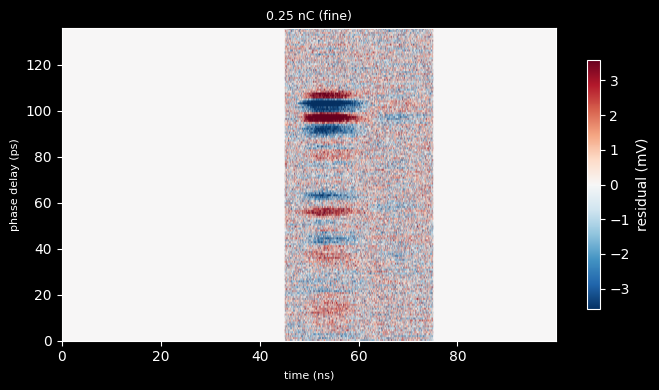

Saved Results/heatmaps/fine_0p25nC_heatmap.png


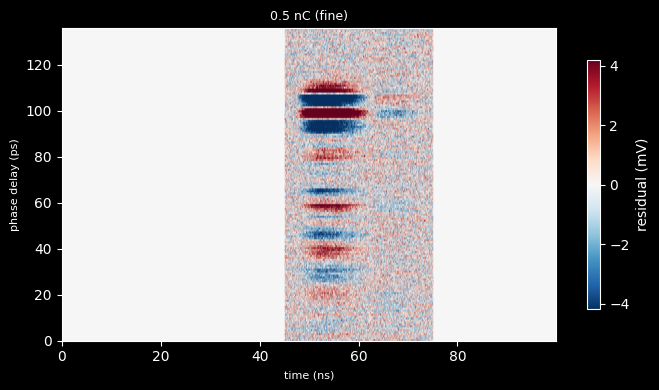

Saved Results/heatmaps/fine_0p5nC_heatmap.png


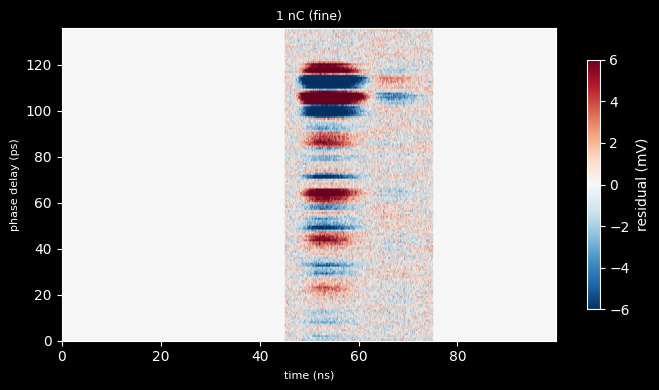

Saved Results/heatmaps/fine_1nC_heatmap.png


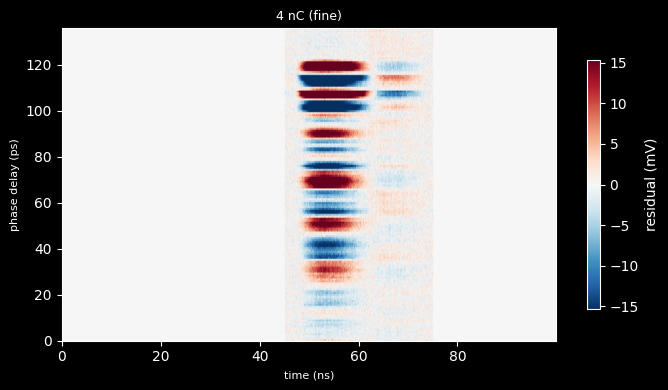

Saved Results/heatmaps/fine_4nC_heatmap.png


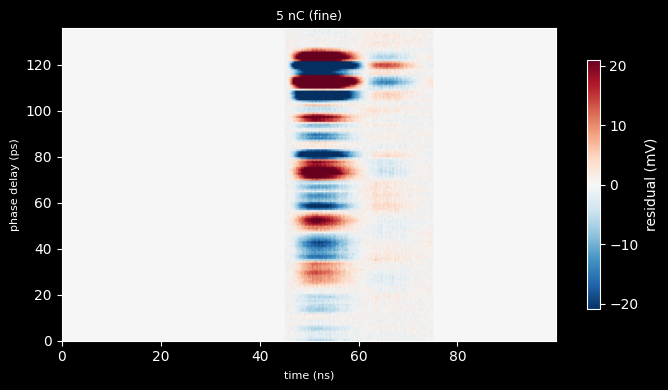

Saved Results/heatmaps/fine_5nC_heatmap.png


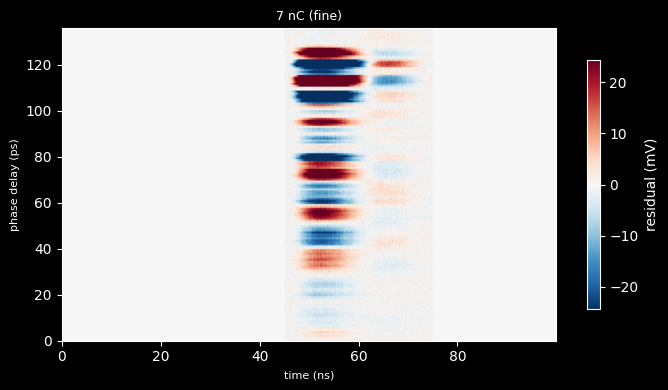

Saved Results/heatmaps/fine_7nC_heatmap.png


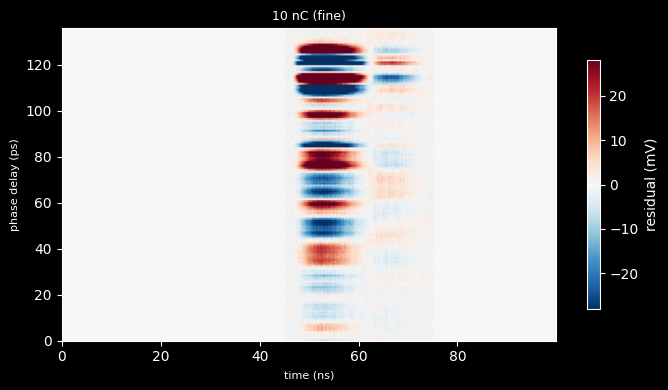

Saved Results/heatmaps/fine_10nC_heatmap.png


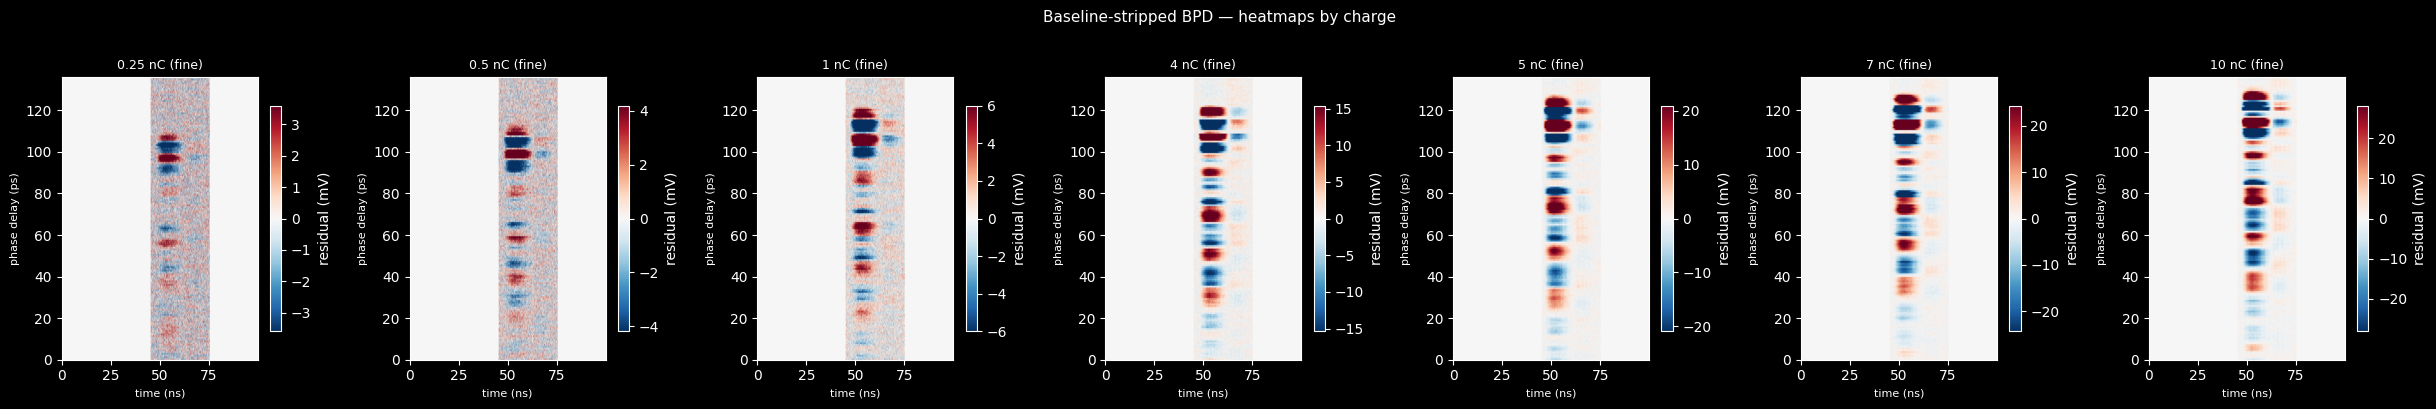

In [37]:
# ── Figure 2: Heatmaps — combined and individual per scan ─────────────────────

def label_to_filename(label):
    """'0.25 nC (fine)' → 'fine_0p25nC'"""
    charge = label.split()[0].replace('.', 'p')
    kind   = 'fine' if 'fine' in label else 'coarse'
    return f'{kind}_{charge}nC'

def draw_heatmap(ax, r, title=None):
    extent = [r['t_ns'][0], r['t_ns'][-1],
              r['delay_ps'][0], r['delay_ps'][-1]]
    vmax = np.percentile(np.abs(mV * r['residual']), 98)
    im = ax.imshow(mV * r['residual'], aspect='auto', extent=extent,
                   origin='lower', cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.set_title(title or r['label'], fontsize=9)
    ax.set_xlabel('time (ns)', fontsize=8)
    ax.set_ylabel('phase delay (ps)', fontsize=8)
    plt.colorbar(im, ax=ax, label='residual (mV)', shrink=0.8)

# ── Individual file per fine scan ─────────────────────────────────────────────
if show_fine:
    for r in results_fine:
        fig, ax = plt.subplots(figsize=(7, 4))
        draw_heatmap(ax, r)
        plt.tight_layout()
        fname = f'{HEATMAP_DIR}/{label_to_filename(r["label"])}_heatmap.png'
        plt.savefig(fname, dpi=200, bbox_inches='tight')
        plt.show()
        print(f'Saved {fname}')

# ── Combined overview figure (all groups) ─────────────────────────────────────
groups  = [g for g, show in [(results_coarse, show_coarse), (results_fine, show_fine)] if show]
n_cols  = max(len(g) for g in groups)
n_rows  = len(groups)
fig     = plt.figure(figsize=(3.5 * n_cols, 4 * n_rows))

subplot_idx = 1
for grp in groups:
    for r in grp:
        ax = fig.add_subplot(n_rows, n_cols, subplot_idx)
        draw_heatmap(ax, r)
        subplot_idx += 1

plt.suptitle('Baseline-stripped BPD — heatmaps by charge', y=1.01, fontsize=11)
plt.tight_layout()
plt.savefig(f'{HEATMAP_DIR}/charge_comparison_heatmaps.png', dpi=200, bbox_inches='tight')
plt.show()

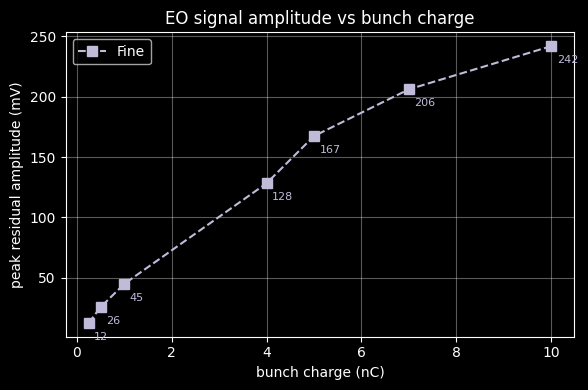

In [38]:
# ── Figure 3: Peak amplitude vs bunch charge ───────────────────────────────────

def extract_charge(label):
    """Parse numeric charge (nC) from label strings like '4 nC (fine)'."""
    return float(label.split()[0])

fig, ax = plt.subplots(figsize=(6, 4))

if show_coarse:
    qc = [extract_charge(r['label']) for r in results_coarse]
    pc = [mV * r['amplitude'].max() for r in results_coarse]
    ax.plot(qc, pc, 'C0o-', lw=1.5, markersize=7, label='Coarse')
    for q, p in zip(qc, pc):
        ax.annotate(f'{p:.0f}', xy=(q, p), xytext=(4, 4),
                    textcoords='offset points', fontsize=8, color='C0')

if show_fine:
    qf = [extract_charge(r['label']) for r in results_fine]
    pf = [mV * r['amplitude'].max() for r in results_fine]
    ax.plot(qf, pf, 'C2s--', lw=1.5, markersize=7, label='Fine')
    for q, p in zip(qf, pf):
        ax.annotate(f'{p:.0f}', xy=(q, p), xytext=(4, -12),
                    textcoords='offset points', fontsize=8, color='C2')

ax.set_xlabel('bunch charge (nC)')
ax.set_ylabel('peak residual amplitude (mV)')
ax.set_title('EO signal amplitude vs bunch charge')
ax.legend()
ax.grid(True, alpha=0.35)
plt.tight_layout()
plt.savefig('charge_comparison_scaling.png', dpi=200)
plt.show()

In [39]:

# ── Linear regression: EO amplitude vs bunch charge ───────────────────────────
# Physically the EO signal should scale linearly through the origin (V ∝ E-field ∝ Q).
# We fit both a free-intercept line and a forced-through-origin line and compare.
#
# Coarse and fine series are fitted separately: different ND filter positions mean
# different laser power on the detector, so their absolute sensitivities differ.
#
# Sensitivity = slope of the fit, units: mV / nC

from scipy import stats

def linear_regression(charges, amplitudes_mV):
    """
    Returns a dict with both the free and origin-forced fits.

    Free fit   uses scipy.stats.linregress → slope, intercept, R², slope stderr.
    Origin fit uses the OLS closed form:  slope = Σ(Q·S) / Σ(Q²),
               with stderr from residuals about that line.
    """
    Q = np.array(charges)
    S = np.array(amplitudes_mV)

    # Free fit
    res         = stats.linregress(Q, S)
    slope_f     = res.slope
    intercept_f = res.intercept
    stderr_f    = res.stderr
    r2_f        = res.rvalue ** 2

    # Origin-forced fit (OLS exact formula)
    slope_o  = (Q * S).sum() / (Q * Q).sum()
    resid_o  = S - slope_o * Q
    # SE of slope for origin regression: sqrt( Σresid² / ((n-1)·Σ Q²) )
    n        = len(Q)
    stderr_o = np.sqrt((resid_o**2).sum() / ((n - 1) * (Q**2).sum()))
    ss_tot   = ((S - S.mean())**2).sum()
    ss_res_o = (resid_o**2).sum()
    r2_o     = 1 - ss_res_o / ss_tot

    return {
        'Q': Q, 'S': S,
        'free':   {'slope': slope_f,  'intercept': intercept_f, 'stderr': stderr_f,  'r2': r2_f},
        'origin': {'slope': slope_o,  'intercept': 0.0,         'stderr': stderr_o,  'r2': r2_o},
    }


def extract_charge(label):
    return float(label.split()[0])


# Collect (charge, peak amplitude) pairs for each group
fits = {}
if show_coarse:
    Qc = np.array([extract_charge(r['label']) for r in results_coarse])
    Sc = np.array([mV * r['amplitude'].max() for r in results_coarse])
    fits['Coarse'] = linear_regression(Qc, Sc)

if show_fine:
    Qf = np.array([extract_charge(r['label']) for r in results_fine])
    Sf = np.array([mV * r['amplitude'].max() for r in results_fine])
    fits['Fine'] = linear_regression(Qf, Sf)


# ── Print results ─────────────────────────────────────────────────────────────
print(f"{'Group':<10}  {'Fit type':<14}  {'Sensitivity (mV/nC)':>22}  {'Intercept (mV)':>16}  R²")
print('-' * 80)
for name, fit in fits.items():
    for fit_type, key in [('Free',   'free'), ('Origin', 'origin')]:
        d = fit[key]
        ic = f"{d['intercept']:+.1f}" if key == 'free' else '  (fixed 0)'
        print(f"{name:<10}  {fit_type:<14}  "
              f"{d['slope']:>12.2f} ± {d['stderr']:.2f}          "
              f"{ic:>16}  {d['r2']:.4f}")
    print()


Group       Fit type           Sensitivity (mV/nC)    Intercept (mV)  R²
--------------------------------------------------------------------------------
Fine        Free                   24.55 ± 2.04                     +20.8  0.9666
Fine        Origin                 27.56 ± 1.61                 (fixed 0)  0.9413



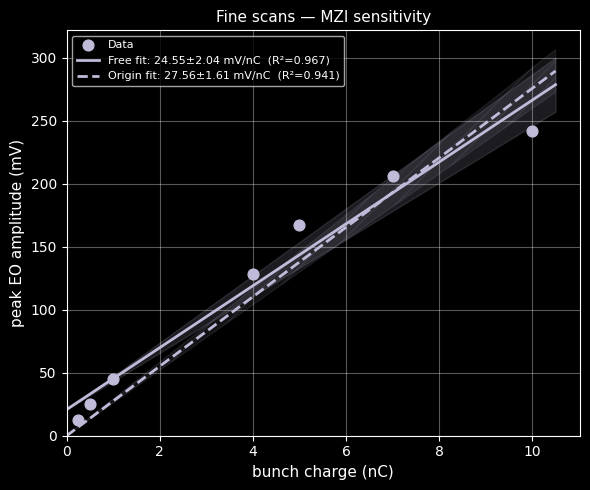

In [40]:

# ── Figure 4: Sensitivity fit plot ────────────────────────────────────────────
# Shows data points, the free-intercept fit line, the origin-forced fit line,
# and a ±1σ confidence band around each.  Separate panels per scan type.

n_panels = len(fits)
fig, axes = plt.subplots(1, n_panels, figsize=(6 * n_panels, 5), squeeze=False)

palette = {'Coarse': 'C0', 'Fine': 'C2'}

for ax, (name, fit) in zip(axes[0], fits.items()):
    col   = palette.get(name, 'C0')
    Q     = fit['Q']
    S     = fit['S']
    Q_fit = np.linspace(0, Q.max() * 1.05, 300)

    # Data points
    ax.scatter(Q, S, color=col, zorder=5, s=60, label='Data')

    # Free fit + 1σ band
    ff = fit['free']
    S_fit_f = ff['slope'] * Q_fit + ff['intercept']
    ax.plot(Q_fit, S_fit_f, color=col, lw=2,
            label=f"Free fit: {ff['slope']:.2f}±{ff['stderr']:.2f} mV/nC  (R²={ff['r2']:.3f})")
    ax.fill_between(Q_fit,
                    (ff['slope'] - ff['stderr']) * Q_fit + ff['intercept'],
                    (ff['slope'] + ff['stderr']) * Q_fit + ff['intercept'],
                    color=col, alpha=0.15)

    # Origin-forced fit + 1σ band
    fo = fit['origin']
    S_fit_o = fo['slope'] * Q_fit
    ax.plot(Q_fit, S_fit_o, color=col, lw=2, ls='--',
            label=f"Origin fit: {fo['slope']:.2f}±{fo['stderr']:.2f} mV/nC  (R²={fo['r2']:.3f})")
    ax.fill_between(Q_fit,
                    (fo['slope'] - fo['stderr']) * Q_fit,
                    (fo['slope'] + fo['stderr']) * Q_fit,
                    color=col, alpha=0.10, hatch='//')

    ax.set_xlabel('bunch charge (nC)', fontsize=11)
    ax.set_ylabel('peak EO amplitude (mV)', fontsize=11)
    ax.set_title(f'{name} scans — MZI sensitivity', fontsize=11)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.35)
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig('sensitivity_fit.png', dpi=200)
plt.show()
